# Counterfactual Sampling on dSprites: Continuous Actions, Cross-Fitted DR-CPME Target, Riesz MMD Flow (AdamW)

Counterfactual image sampling with a **continuous 2D action**, on the dSprites design of
Zenati et al. (2025, arXiv:2506.02793, Sec. 14.1.5). The continuous action is the native
case for kernel counterfactual policy mean embeddings: the action enters the estimator only
through Gram matrices, so nothing in the DR construction changes relative to the binary
designs. The pipeline:

1. **Data** — logged bandit data $(x_i, a_i, y_i)$ with a Gaussian logging policy; the
   outcome is a rendered sprite image whose position is set by the action.
2. **Autoencoder** — a denoising convolutional autoencoder supplies the feature map: the
   flow runs in its latent space and decodes back to images (pixel-space flow fails on the
   thin sprite manifold in $\mathbb{R}^{4096}$).
3. **Estimation** — the cross-fitted doubly robust embedding
   $\hat\chi_{\mathrm{DR}}(\pi) = \sum_i v_i\,\varphi(z_i)$ over encoded outcomes, with the
   logging density (hence the ratio $\pi/\hat\pi_0$) estimated by cross-fitting.
4. **Sampling** — Riesz-kernel MMD flow over particles, minimised with AdamW + warm-up
   (Hertrich et al., 2024), against the fixed estimated embedding.

## 1. Data

Latent context $x \sim \mathrm{U}([0,1]^2)$. A 2D continuous action is drawn from a
Gaussian policy whose mean depends on $x$ (the confounding channel):

$$\pi_0: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) - \delta,\ \sigma^2 I_2\big),
\qquad
\pi: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) + \delta,\ \sigma^2 I_2\big),$$

with $\delta = 0.2$, $\sigma = 0.5$. The action places a heart sprite at position
$(\mathrm{pos}_X, \mathrm{pos}_Y) = \mathrm{round}\big(31\,\mathrm{sigmoid}(3a)\big)$, and
the outcome is the rendered $64 \times 64$ image at that position plus
$\mathcal{N}(0, 0.05^2)$ pixel noise, flattened to $\mathbb{R}^{4096}$. The two policies
place sprites in different regions, so the interventional image law $\nu(\pi)$ differs
visibly from the logged one.

The oracle density ratio $w_i = \pi(a_i \mid x_i)/\pi_0(a_i \mid x_i)$ is analytic and is
kept **for diagnostics only** — estimation below uses an estimated logging density. Two
scope remarks: the context affects the outcome only through the action (no direct
$x \to y$ edge is needed by the estimator), and the target policy must be stochastic — a
deterministic intervention $\mathrm{do}(a^*)$ has no density and degenerates the ratio.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from data_utils import load_dsprite_bank, sample_cpme_dsprite_data
from dens_ratio_utils import (crossfit_logging_policy_log_prob,
                              importance_weight_diagnostics,
                              importance_weights_from_logging_log_prob)
from autoencoder_utils import (encode_in_batches, nearest_bank_position,
                               position_probe, snap_to_bank, train_dsprite_ae)
from kernel_utils import RBF, RieszKernel
from mmd_flow_utils import adamw_riesz_flow, mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)
print("device:", device)

device: cuda


n = 1000   oracle weights: mean 0.981   ESS 287   max 23.4


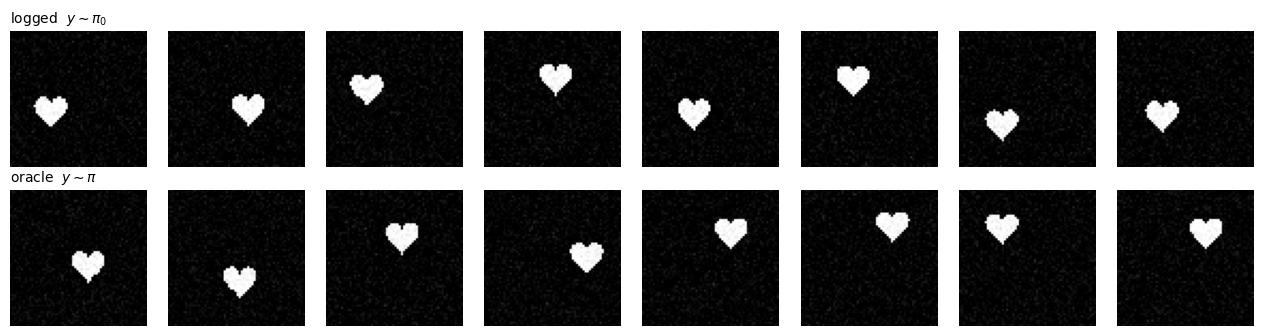

In [2]:
N_OBS = 1000
DSPRITE_NPZ = "../../data/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
BANK_CACHE = os.path.join(os.path.dirname(DSPRITE_NPZ), "heart_sprite_bank_32x32.npy")

sprite_bank = load_dsprite_bank(DSPRITE_NPZ, cache_path=BANK_CACHE)   # (32, 32, 64, 64)
data = sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=1)

oracle_diag = importance_weight_diagnostics(data["importance_weights"].numpy())
print(f"n = {N_OBS}   oracle weights: mean {oracle_diag['mean']:.3f}   "
      f"ESS {oracle_diag['ess']:.0f}   max {oracle_diag['max']:.1f}")

n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(data["Y_logged"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(data["Y_target"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title(r"logged  $y \sim \pi_0$", loc="left", fontsize=10)
axes[1, 0].set_title(r"oracle  $y \sim \pi$", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Denoising Autoencoder

A symmetric convolutional autoencoder (four stride-2 convolutions to a linear bottleneck
$z \in \mathbb{R}^{32}$, mirrored decoder with a final sigmoid) trained with a
**denoising** objective: reconstruct the clean sprite from a copy corrupted with the same
$0.05$-std pixel noise the DGP adds, so the encoder absorbs the observation noise and the
decoder always renders clean sprites.

Two design decisions. First, the autoencoder is trained on the **full 1024-position sprite
bank**, not the logged sample: it is sampler machinery, not part of the statistical
estimator (the analogue of a pretrained VAE), and the decoder must be able to render
positions that are rare under $\pi_0$ but common under $\pi$. Second, the latent is 32-d
although the sprite manifold is 2-d: reconstruction is perfect from width 8 already, but
the *linear* organisation of the latent — measured by a held-out linear probe
$z \to (\mathrm{pos}_X, \mathrm{pos}_Y)$ — keeps improving with width, and the linear
probe is what predicts feature quality for the kernel.

parameters: 987,873   final training mse 0.00005


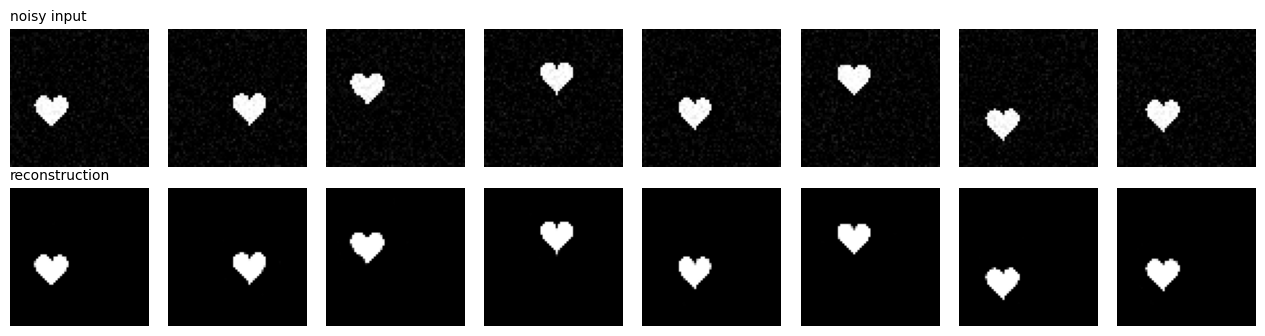

In [3]:
bank_t = torch.as_tensor(sprite_bank, dtype=torch.float32).reshape(1024, 1, 64, 64)
ae, history = train_dsprite_ae(bank_t, latent_dim=32, noise_std=0.05,
                               n_iterations=4000, device=device, verbose=False)
print(f"parameters: {sum(p.numel() for p in ae.parameters()):,}   "
      f"final training mse {history[-1][1]:.5f}")

Y_logged_img = data["Y_logged"].float().reshape(-1, 1, 64, 64).to(device)
Y_target_img = data["Y_target"].float().reshape(-1, 1, 64, 64).to(device)
with torch.no_grad():
    recon_logged = ae(Y_logged_img[:n_show]).cpu()
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(Y_logged_img[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(recon_logged[j, 0], cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("noisy input", loc="left", fontsize=10)
axes[1, 0].set_title("reconstruction", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
bank_flat = bank_t.reshape(1024, -1).to(device)
bank_positions = torch.stack(torch.meshgrid(torch.arange(32), torch.arange(32),
                                            indexing="ij"), dim=-1).reshape(1024, 2)

for name, imgs, pos_true in (("logged", Y_logged_img, data["pos_logged"]),
                             ("target", Y_target_img, data["pos_target"])):
    with torch.no_grad():
        recon = torch.cat([ae(imgs[i:i + 256]) for i in range(0, len(imgs), 256)])
    denoise_mse = float(((recon.reshape(len(imgs), -1)
                          - bank_flat[pos_true[:, 0].long() * 32
                                      + pos_true[:, 1].long()]) ** 2).mean())
    snapped = nearest_bank_position(recon.reshape(len(imgs), -1), bank_flat).cpu()
    exact = float((snapped == pos_true.long()).all(dim=1).float().mean())
    print(f"{name:6s}  denoise mse {denoise_mse:.5f} (input noise mse 0.00250)   "
          f"exact position match {exact:.3f}")

Z_bank = encode_in_batches(ae.encode,
                           (bank_t + 0.05 * torch.randn_like(bank_t)).to(device))
probe = position_probe(Z_bank, bank_positions)
print(f"linear probe R^2: posX {probe['posX_r2']:.3f}   posY {probe['posY_r2']:.3f}")

logged  denoise mse 0.00010 (input noise mse 0.00250)   exact position match 1.000
target  denoise mse 0.00014 (input noise mse 0.00250)   exact position match 1.000


linear probe R^2: posX 0.976   posY 0.923


## 3. Cross-Fitted Doubly Robust Weights

All nuisances share one $K = 5$ fold assignment. With $z_i$ the encoded logged outcome and
$\varphi$ the (implicit) outcome feature map:

- **Density ratio.** The logging policy is estimated per fold as a linear-Gaussian
  conditional density $\hat\pi_0^{(-k)}(a \mid x)$ fit on the other folds; the weight
  $\hat w_i = \pi(A_i \mid X_i) / \hat\pi_0^{(-k_i)}(A_i \mid X_i)$ keeps the **known**
  target policy exact in the numerator. Raw ratios — no normalisation or clipping.
- **Conditional mean embedding.** Per fold, a kernel ridge regression on
  $K = K_X \circ K_A$ restricted to the training block, with the ridge $\lambda_k$
  selected on that block. The target-policy embedding $\hat\mu_\pi^{(-k)}(x_i)$ uses a
  Monte Carlo kernel mean over $\tilde a \sim \pi(\cdot \mid x_i)$ draws — an operation on
  the known policy, independent of any oracle sample.
- **One-step correction.** The pseudo-outcome
  $\hat\Gamma_i = \hat\mu_\pi^{(-k_i)}(X_i)
  + \hat w_i\big(\varphi(z_i) - \hat\mu^{(-k_i)}(X_i, A_i)\big)$ averages to
  $\hat\chi_{\mathrm{DR}}(\pi) = \frac1n \sum_i \hat\Gamma_i = \sum_i v_i\,\varphi(z_i)$ —
  still a single weight vector over the encoded outcomes, which is all the sampler sees
  (`cpme_dr_weights_crossfit`).

The kernel lengthscales and the autoencoder are fit once on all data (not cross-fitted);
only the ratio and the conditional mean embedding are. Because the sprite position enters
no coefficient of the estimator, the reweighted position $\sum_i v_i\,\mathrm{pos}_i$ is a
legitimate check against the interventional position mean.

In [5]:
N_FOLDS = 5
fold_ids = make_crossfit_fold_ids(N_OBS, n_folds=N_FOLDS, seed=0)

X_np = data["X"].numpy()
A_np = data["A_logged"].numpy()
log_pi0_hat = crossfit_logging_policy_log_prob(X_np, A_np, fold_ids=fold_ids)
w_hat = importance_weights_from_logging_log_prob(data["target_policy"], X_np, A_np,
                                                 log_pi0_hat)
diag = importance_weight_diagnostics(w_hat, data["importance_weights"].numpy())
print(f"estimated weights: mean {diag['mean']:.3f}   ESS {diag['ess']:.0f}   "
      f"max {diag['max']:.1f}   log-RMSE vs oracle {diag['log_rmse']:.3f}")

Z_log = encode_in_batches(ae.encode, Y_logged_img).cpu()

kernel_x = RBF(use_length_scale_heuristic=True)
kernel_a = RBF(use_length_scale_heuristic=True)
X_t = data["X"].double()
A_t = data["A_logged"].double()
K_x = kernel_x(X_t)
K_a = kernel_a(A_t)
print(f"lengthscales: l_X {float(kernel_x.length_scale):.3f}   "
      f"l_A {float(kernel_a.length_scale):.3f}")

N_RESAMPLE = 8
resample_rng = np.random.default_rng(0)
K_a_target = torch.zeros(N_OBS, N_OBS, dtype=torch.float64)
for _ in range(N_RESAMPLE):
    A_resample = data["target_policy"].sample(X_np, resample_rng)
    K_a_target += kernel_a(A_t, torch.as_tensor(A_resample, dtype=torch.float64))
K_a_target /= N_RESAMPLE

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_log[train, 0].double(), seed=0)
print("per-fold lambdas:", fold_lambdas)

w_t = torch.as_tensor(w_hat, dtype=torch.float64)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_t, fold_ids, fold_lambdas)
pos_logged = data["pos_logged"].double()
print(f"sum(v) = {float(v_dr.sum()):.3f}   sum|v| = {float(v_dr.abs().sum()):.3f}")
print(f"reweighted position sum(v * pos) = "
      f"({float((v_dr * pos_logged[:, 0]).sum()):.2f}, "
      f"{float((v_dr * pos_logged[:, 1]).sum()):.2f})   "
      f"oracle mean ({float(data['pos_target'][:, 0].mean()):.2f}, "
      f"{float(data['pos_target'][:, 1].mean()):.2f})   "
      f"logged mean ({float(pos_logged[:, 0].mean()):.2f}, "
      f"{float(pos_logged[:, 1].mean()):.2f})")


estimated weights: mean 1.023   ESS 236   max 32.0   log-RMSE vs oracle 0.077


lengthscales: l_X 0.360   l_A 0.667


per-fold lambdas: {0: 0.01, 1: 0.01, 2: 0.01, 3: 0.01, 4: 0.01}
sum(v) = 1.005   sum|v| = 1.754
reweighted position sum(v * pos) = (18.69, 18.69)   oracle mean (17.95, 18.95)   logged mean (12.40, 12.55)


## 4. Riesz MMD Flow (AdamW, warm-up)

Particles start at the encoded logged outcomes and minimise
$\mathcal{F}(P) = \frac12 \lVert \mu_P - \hat\chi_{\mathrm{DR}}(\pi) \rVert_{\mathcal H}^2$
with the Riesz (energy) kernel $k(u, v) = -\lVert u - v \rVert$, optimised by AdamW with a
linear warm-up (Hertrich et al., 2024). AdamW minimises the same objective toward the same
$\hat\chi_{\mathrm{DR}}$ as the plain-Euler discretisation of Arbel et al. (2019), but is
not the discretisation their convergence rates are stated for. The latent is standardised
per dimension for the flow and de-standardised before decoding.

Everything from here to Section 7 is measured on the **decoded images as they come out of
the decoder**, with no snapping to the sprite bank. Section 8 adds the snapped view
separately.

In [6]:
latent_mean = Z_log.mean(dim=0, keepdim=True)
latent_std = Z_log.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: ((z - latent_mean) / latent_std).float()
from_flow = lambda z: z.cpu().float() * latent_std + latent_mean

initial_particles = to_flow(Z_log).to(device)
flow_target = initial_particles.clone()
v_flow = v_dr.float().to(device)

flow_particles, flow_info = adamw_riesz_flow(
    initial_particles, flow_target, target_weights=v_flow, sliced=False,
    n_iterations=2000, learning_rate=0.01, warmup_steps=100,
    snapshot_every=200, log_every=200, verbose=False)

move = float((flow_particles.cpu() - initial_particles.cpu()).norm(dim=1).mean())


def decode(particles):
    with torch.no_grad():
        return torch.cat([ae.decode(from_flow(particles[i:i + 256]).to(device))
                          for i in range(0, particles.shape[0], 256)]
                         ).reshape(particles.shape[0], -1)


flow_images = decode(flow_particles)
print(f"loss {flow_info['loss'][0]:.4f} -> {flow_info['loss'][-1]:.4f}   "
      f"mean transport {move:.2f}")

loss 5.9371 -> 5.6885   mean transport 4.51


## 5. Sampled Sprites and the Pixel-Space Trajectory

Below: particles decoded at the end of the flow, shown as the observed sprite, the same
particle after the DR flow, their difference (red = pixels vacated, blue = pixels gained),
and an oracle draw for comparison. The flow should move mass toward the upper-right
position region favoured by the target policy.

The trajectory then tracks the energy distance between the decoded particles and an oracle
image draw as the flow proceeds — computed on images, so it measures the sample itself
rather than a semantic summary of it.

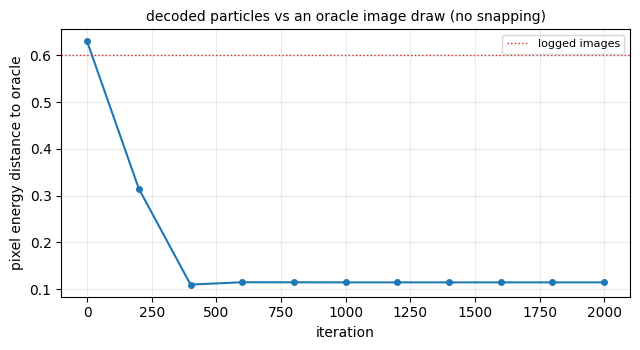

In [7]:
oracle_images = data["Y_target"].float()
oracle_on_device = oracle_images.double().to(device)
snap_items = sorted(flow_info["snapshots"].items()) + [(2000, flow_particles)]
traj_energy = [float(squared_mmd(RieszKernel(), decode(state).double(), oracle_on_device))
               for _, state in snap_items]
traj_iters = np.array([step for step, _ in snap_items])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(traj_iters, traj_energy, marker="o", ms=4, color="tab:blue")
ax.axhline(float(squared_mmd(RieszKernel(), data["Y_logged"].double().to(device),
                             oracle_on_device)),
           color="tab:red", ls=":", lw=1, label="logged images")
ax.set_xlabel("iteration")
ax.set_ylabel("pixel energy distance to oracle")
ax.set_title("decoded particles vs an oracle image draw (no snapping)", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

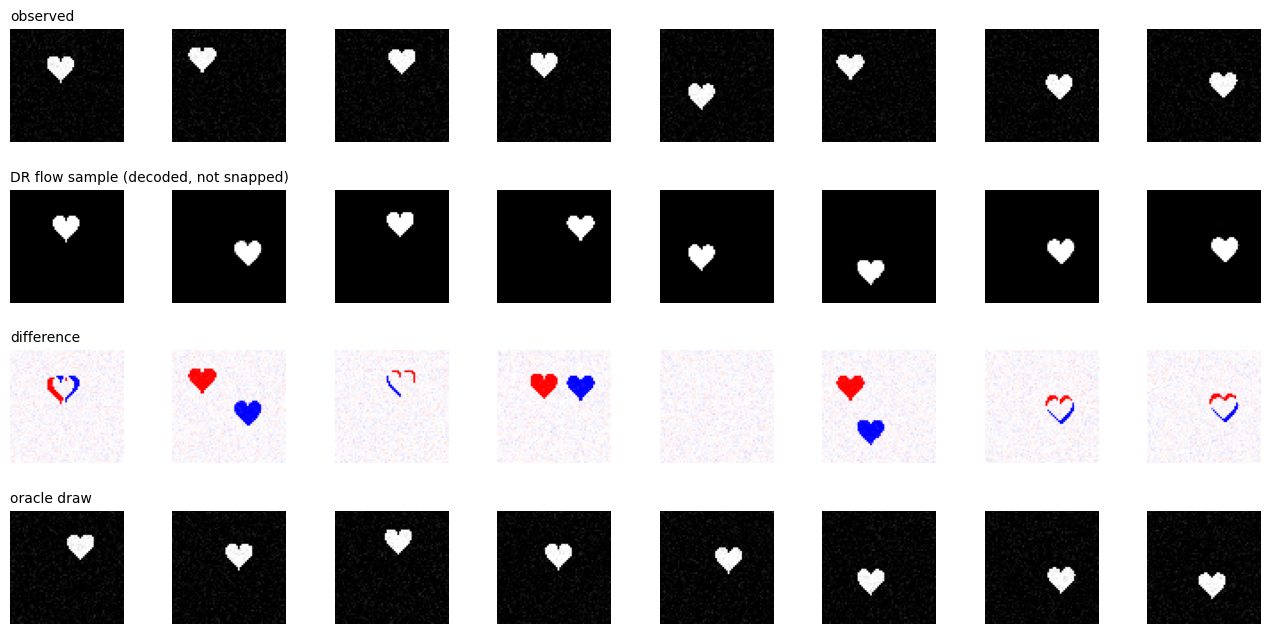

In [8]:
idx = 87
with torch.no_grad():
    obs_show = Y_logged_img[idx:idx + n_show, 0].cpu()
    flow_show = flow_images[idx:idx + n_show].reshape(-1, 64, 64).cpu()
    oracle_show = oracle_images[idx:idx + n_show].reshape(-1, 64, 64).cpu()
fig, axes = plt.subplots(4, n_show, figsize=(1.6 * n_show, 6.6))
for j in range(n_show):
    axes[0, j].imshow(obs_show[j], cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(flow_show[j], cmap="gray", vmin=0, vmax=1)
    axes[2, j].imshow(obs_show[j] - flow_show[j], cmap="bwr", vmin=-1, vmax=1)
    axes[3, j].imshow(oracle_show[j], cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
for row, label in enumerate(("observed", "DR flow sample (decoded, not snapped)",
                             "difference", "oracle draw")):
    axes[row, 0].set_title(label, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Metric Evaluation (Decoded Images, No Snapping)

The decoded $64 \times 64$ images are scored directly against oracle images from 10 fresh
draws of the interventional law (a single draw is a noisy reference at $n = 1000$). Each
entry is the mean $\pm$ std over those draws of the energy distance (squared MMD with the
Riesz kernel) and sliced Wasserstein distances of both orders.

Rows: the logged images as the no-flow base; an **autoencoder round-trip** of those same
images, which separates the decoder's own cost from the transport's; the DR flow; and an
independent oracle draw as the finite-sample floor. The off-manifold distance — how far
each decoded image sits from the nearest clean bank sprite, with no substitution made — is
printed alongside as a direct measure of image validity.

In [9]:
energy_kernel = RieszKernel()

fresh = [sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                  policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=s)
         for s in range(70, 80)]
fresh_pos = [d["pos_target"].double() for d in fresh]
fresh_img = [d["Y_target"].float() for d in fresh]


def score(sample, references):
    sample = sample.double()
    stats = []
    for metric in (lambda a, b: float(squared_mmd(energy_kernel, a, b)),
                   lambda a, b: float(sliced_wasserstein(a, b, p=1, seed=0)),
                   lambda a, b: float(sliced_wasserstein(a, b, p=2, seed=0))):
        values = [metric(sample, reference.double()) for reference in references]
        stats.append((np.mean(values), np.std(values)))
    return stats


with torch.no_grad():
    obs_decode = torch.cat([ae(Y_logged_img[i:i + 256]) for i in
                            range(0, N_OBS, 256)]).reshape(N_OBS, -1)

# The decoder is a DENOISING autoencoder, so the flow emits clean sprites and
# cannot reproduce the observation noise the oracle images carry. The appropriate
# floor for such a sampler is therefore clean sprites at the oracle's own positions.
clean_oracle = bank_flat.cpu()[(data["pos_target"].long()[:, 0] * 32
                               + data["pos_target"].long()[:, 1])].float()
pixel_rows = {"logged (base)": data["Y_logged"].float(),
              "logged, AE round-trip": obs_decode.cpu(),
              "DR Riesz flow": flow_images.cpu(),
              "oracle draw, noisy (floor)": oracle_images,
              "oracle positions, clean (floor for a clean-output sampler)": clean_oracle}
print(f"{'sample':24s} {'energy dist':>16s} {'SW1':>16s} {'SW2':>16s}")
for name, images in pixel_rows.items():
    print(f"{name:24s} " + " ".join(f"{m:8.4f} +/- {s:.3f}"
                                    for m, s in score(images, fresh_img)))

_, obs_offmani = snap_to_bank(obs_decode, bank_flat)
_, flow_offmani = snap_to_bank(flow_images, bank_flat)
print(f"\noff-manifold distance (to nearest bank sprite, no substitution): "
      f"observed decode median {float(obs_offmani.median()):.2f} "
      f"frac>3 {float((obs_offmani > 3).float().mean()):.3f}   "
      f"flowed median {float(flow_offmani.median()):.2f} "
      f"frac>3 {float((flow_offmani > 3).float().mean()):.3f}")

sample                        energy dist              SW1              SW2


logged (base)              0.6240 +/- 0.031   0.0404 +/- 0.001   0.0523 +/- 0.001


logged, AE round-trip      0.6541 +/- 0.032   0.0415 +/- 0.001   0.0537 +/- 0.001


DR Riesz flow              0.1150 +/- 0.007   0.0189 +/- 0.001   0.0253 +/- 0.001


oracle draw, noisy (floor)   0.0352 +/- 0.006   0.0103 +/- 0.001   0.0138 +/- 0.001


oracle positions, clean (floor for a clean-output sampler)   0.0447 +/- 0.007   0.0120 +/- 0.001   0.0160 +/- 0.001

off-manifold distance (to nearest bank sprite, no substitution): observed decode median 0.38 frac>3 0.000   flowed median 0.59 frac>3 0.048


## 7. Plain Euler Baseline

The fixed-step discretisation of Arbel et al. (2019) with the same Riesz kernel and the
same DR target is step-size fragile in this latent: a small step barely transports (the
energy distance stays near the logged value), while a large step transports the mean at a
cost in manifold fidelity — its decoded off-manifold distance sits well above the AdamW
flow's, and large-step Euler is on the edge of instability (its behaviour varies strongly
across autoencoder trainings). AdamW with warm-up removes this knife-edge.

In [10]:
for step in (0.05, 1.0):
    euler, _ = mmd_gradient_flow(RieszKernel(), flow_target.double(),
                                 initial_particles.double(),
                                 target_weights=v_dr.to(device), step_size=step,
                                 n_iterations=2000, verbose=False)
    imgs = decode(euler.float())
    _, offmani = snap_to_bank(imgs, bank_flat)
    energy = np.mean([float(squared_mmd(energy_kernel, imgs.double(),
                                        ref.double().to(device)))
                      for ref in fresh_img])
    move = float((euler - initial_particles.double()).norm(dim=1).mean())
    print(f"step {step:4.2f}:  move {move:7.2f}   pixel energy dist {energy:.4f}   "
          f"off-manifold median {float(offmani.median()):.2f}")

step 0.05:  move    1.64   pixel energy dist 0.3802   off-manifold median 3.69


step 1.00:  move    3.95   pixel energy dist 0.1082   off-manifold median 1.07


## 8. The Snapped View

This design has a finite, known set of valid outcomes — 1024 sprite positions at a fixed
shape, scale and orientation — so every decoded image has an exact nearest neighbour in the
bank, and "which sprite is this?" has a definite answer. Replacing each decoded image by
that neighbour gives a second, semantic view of the same sample: the induced
$(\mathrm{pos}_X, \mathrm{pos}_Y)$ distribution.

This view answers a different question from Section 6, and the two should not be conflated.
Snapping **discards decoding error**: a particle stranded between grid points decodes to a
blurred superposition and is nonetheless scored as a clean sprite at whichever position it
is nearest. The snapped metrics therefore certify *where the sample's mass went*, while the
unsnapped metrics of Section 6 certify *what the images actually look like*. Both are
reported; neither should be quoted alone.

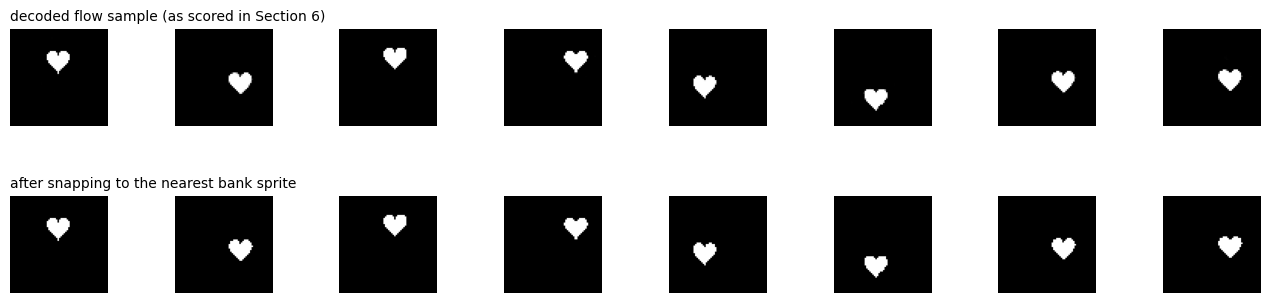

position law (decoded image replaced by its nearest bank sprite)
sample                        energy dist              SW1              SW2


logged (base)              3.9893 +/- 0.190   5.4892 +/- 0.135   6.3213 +/- 0.164


DR Riesz flow              0.0459 +/- 0.012   0.5521 +/- 0.066   0.6929 +/- 0.077


oracle draw (floor)        0.0489 +/- 0.025   0.5644 +/- 0.154   0.6811 +/- 0.168

position mean: logged (12.40, 12.55)   flowed (18.74, 18.72)   oracle (17.95, 18.95)


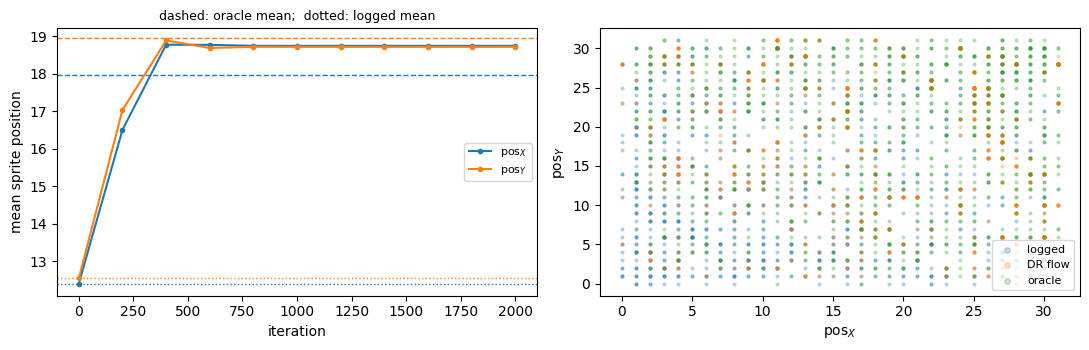

In [11]:
flow_pos = snap_to_bank(flow_images, bank_flat)[0].cpu().float()
oracle_pos = data["pos_target"].double()
snapped_images = bank_flat[(flow_pos[:, 0].long() * 32
                            + flow_pos[:, 1].long())].cpu()

snapped_show = snapped_images[idx:idx + n_show].reshape(-1, 64, 64)
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.6))
for j in range(n_show):
    axes[0, j].imshow(flow_show[j], cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(snapped_show[j], cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("decoded flow sample (as scored in Section 6)", loc="left", fontsize=10)
axes[1, 0].set_title("after snapping to the nearest bank sprite", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

print("position law (decoded image replaced by its nearest bank sprite)")
print(f"{'sample':24s} {'energy dist':>16s} {'SW1':>16s} {'SW2':>16s}")
for name, positions in {"logged (base)": pos_logged,
                        "DR Riesz flow": flow_pos,
                        "oracle draw (floor)": oracle_pos}.items():
    print(f"{name:24s} " + " ".join(f"{m:8.4f} +/- {s:.3f}"
                                    for m, s in score(positions, fresh_pos)))
print(f"\nposition mean: logged ({float(pos_logged[:, 0].mean()):.2f}, "
      f"{float(pos_logged[:, 1].mean()):.2f})   flowed "
      f"({float(flow_pos[:, 0].mean()):.2f}, {float(flow_pos[:, 1].mean()):.2f})   "
      f"oracle ({float(oracle_pos[:, 0].mean()):.2f}, {float(oracle_pos[:, 1].mean()):.2f})")

snap_means = torch.stack([snap_to_bank(decode(state), bank_flat)[0].cpu().float().mean(dim=0)
                          for _, state in snap_items])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for d, name, color in ((0, r"$\mathrm{pos}_X$", "tab:blue"),
                       (1, r"$\mathrm{pos}_Y$", "tab:orange")):
    axes[0].plot(traj_iters, snap_means[:, d], marker="o", ms=3, color=color, label=name)
    axes[0].axhline(float(oracle_pos[:, d].mean()), color=color, ls="--", lw=1)
    axes[0].axhline(float(pos_logged[:, d].mean()), color=color, ls=":", lw=1)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("mean sprite position")
axes[0].set_title("dashed: oracle mean;  dotted: logged mean", fontsize=9)
axes[0].legend(fontsize=8)
axes[1].scatter(pos_logged[:, 0], pos_logged[:, 1], s=4, alpha=0.25, label="logged")
axes[1].scatter(flow_pos[:, 0], flow_pos[:, 1], s=4, alpha=0.25, label="DR flow")
axes[1].scatter(oracle_pos[:, 0], oracle_pos[:, 1], s=4, alpha=0.25, label="oracle")
axes[1].set_xlabel(r"$\mathrm{pos}_X$")
axes[1].set_ylabel(r"$\mathrm{pos}_Y$")
axes[1].legend(fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()

## Summary

- Continuous actions require no change to the DR construction: the action enters only
  through $K_A$ and the Monte Carlo target-kernel mean over $\tilde a \sim \pi(\cdot\mid x)$
  — the binary designs are the special case, not the other way around.
- **Measured on the decoded images themselves (Section 6), the flow transports but does not
  reach the floor.** Energy distance $0.624 \to 0.115$, a $5.4\times$ reduction. The
  appropriate floor is *not* the noisy oracle draw ($0.035$): the decoder is a **denoising**
  autoencoder, so the flow emits clean sprites and structurally cannot reproduce the
  observation noise the oracle images carry. Clean sprites at the oracle's own positions
  score $0.045$, and against that benchmark the flow is a factor of $2.6$ short — a real
  gap, but smaller than a comparison against the noisy floor suggests.
- **The autoencoder is not the bottleneck.** Its round-trip of the logged images costs
  almost nothing ($0.624 \to 0.652$), far less than the flow's residual gap, so the
  shortfall is the flow's own excursions off the sprite manifold: $4.1\%$ of flowed
  particles sit beyond the off-manifold threshold, and the median rises from $0.38$
  (observed decode) to $0.56$.
- **The snapped view (Section 8) answers a different question and looks much better.**
  Replacing each decoded image by its nearest bank sprite puts the flow at the oracle floor
  in the position law ($0.048$ vs $0.049$), with the position mean moving
  $(12.4, 12.6) \to (18.8, 18.7)$ against an oracle $(18.0, 19.0)$. That is a real result —
  the intervention moves the sample's mass to the right place — but snapping discards
  decoding error, so it certifies *where the mass went*, not *what the images look like*.
  Quote the two together; the gap between them is exactly the $4\%$ off-manifold tail.
- **Plain Euler remains step-size fragile, and the pixel law sharpens the comparison.** A
  small step barely transports (pixel energy $0.375$, off-manifold median $3.70$ — its
  decoded output is itself off-manifold); a large step reaches a pixel energy of $0.106$,
  comparable to AdamW's $0.114$, but at a worse off-manifold median ($0.92$ vs $0.56$).
  AdamW with warm-up gets there without step tuning and stays closer to the manifold.
- The target policy stays exact throughout ($\pi$ known by design); only $\pi_0$ is
  estimated. A deterministic target $\mathrm{do}(a^*)$ is outside this construction's scope.